# RQ1 — Utility vs complessità
### *Quanto perdiamo, in accuracy, addestrando su dati sintetici invece che reali?*

> **Domanda di ricerca.** Al crescere della complessità del dataset (numero di feature, cardinalità delle
> variabili categoriche), il divario di utility tra dati sintetici e dati reali si allarga?

**Come lo misuriamo.** Per ogni run lo stesso modello viene addestrato due volte, una su dati reali e una
su dati sintetici. La differenza tra le due accuracy è il nostro indicatore di utility:

$$\Delta_{acc} \;=\; \text{acc}_{synth} - \text{acc}_{real}$$

* **Δ = 0** → il sintetico è utile quanto il reale
* **Δ < 0** → si perde utility (più è negativo, peggio è)

Nel notebook Δ è espresso in **punti percentuali (pp)**: −5 pp significa 5 punti di accuracy in meno.

---

### Guida alla lettura

| # | Sezione | Domanda a cui risponde |
|---|---------|------------------------|
| 1 | Setup | Configurazione, stile grafico, caricamento dati |
| 2 | I dati | Quali dataset e quali run ho? Sono affidabili? |
| 3 | Il quadro generale | Reale vs sintetico: quanto si perde, e rispetto a un modello "ingenuo"? |
| 4 | Δ vs complessità | **La RQ1**: il gap cresce con la complessità? |
| 5 | Fedeltà vs utility | Un sintetico statisticamente fedele è anche più utile? |
| 6 | Costo computazionale | Quanto costa, in tempo, ottenere quell'utility? |
| 7 | Tabella di sintesi | Tutti i numeri in un colpo d'occhio (+ export LaTeX) |
| 8 | Limiti e prossimi passi | Cosa i dati attuali permettono (e non permettono) di dire |



---
## 1 · Setup
Import, palette e stile grafico sono centralizzati qui, così tutti i grafici del notebook restano coerenti
(e per cambiare un colore basta toccare una riga).

In [7]:
import sys, json, ast
from pathlib import Path

# Root del progetto = la prima cartella (da qui in su) che contiene src/. Funziona sia che il kernel
# parta da notebooks/ sia dalla root, così i percorsi non dipendono dalla working directory.
ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "src").is_dir()), Path.cwd())
sys.path.insert(0, str(ROOT))     # per importare src.*

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, PercentFormatter, NullFormatter
from IPython.display import display, Markdown

from src.analysis.aggregate import load_runs_index

# ── Opzioni ────────────────────────────────────────────────────────────────
SAVE_FIGS = False                      # True → salva ogni figura in FIG_DIR (png 300 dpi + pdf)
FIG_DIR   = ROOT / "reports" / "figures" / "rq1"
INDEX_PATH = ROOT / "reports" / "runs_index.jsonl"

# ── Etichette leggibili e palette (colorblind-friendly) ────────────────────
DATASET_LABELS = {"adult_income": "Adult Income", "breast_cancer": "Breast Cancer", "german_credit": "German Credit"}
METHOD_LABELS  = {"gaussian_copula": "Gaussian Copula", "ctgan": "CTGAN"}
METHOD_COLORS  = {"gaussian_copula": "#B70000", "ctgan": "#FF4ADB"}
C_REAL, C_BASE, C_TEXT, C_MUTED = "#264653", "#9AA5B1", "#1F2937", "#6B7280"
_FALLBACK = ["#457B9D", "#E9C46A", "#8E6C8A", "#6D9F71"]   # per metodi non previsti sopra

def label_of(method):  return METHOD_LABELS.get(method, method)
def color_of(method):
    if method in METHOD_COLORS: return METHOD_COLORS[method]
    return _FALLBACK[sorted(set(METHODS) - set(METHOD_COLORS)).index(method) % len(_FALLBACK)]

# ── Stile matplotlib ───────────────────────────────────────────────────────
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "figure.facecolor": "white",
    "font.size": 10.5, "text.color": C_TEXT, "axes.labelcolor": C_TEXT,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#CBD2D9", "xtick.color": C_MUTED, "ytick.color": C_MUTED,
    "axes.grid": True, "grid.color": "#E8ECEF", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})

def finish(fig, name):
    # Chiude la figura: la salva (se SAVE_FIGS) e la mostra.
    if SAVE_FIGS:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        for ext in ("png", "pdf"):
            fig.savefig(FIG_DIR / f"{name}.{ext}")
    plt.show()

def fmt_pp(v):  return f"{v + np.sign(v) * 1e-9:+.1f} pp".replace("-", "−")   # epsilon: evita -9.4499 → -9.4
def fmt_int(n): return f"{int(n):,}".replace(",", ".")

In [8]:
# ── Caricamento e preparazione ─────────────────────────────────────────────
df = load_runs_index(INDEX_PATH)

def _majority_pct(x):
    # % della classe maggioritaria da class_balance_pct (dict o stringa serializzata).
    if isinstance(x, str):
        try:    x = json.loads(x)
        except ValueError: x = ast.literal_eval(x)
    return max(x.values()) if isinstance(x, dict) else np.nan

df["dataset_label"] = df["dataset"].map(DATASET_LABELS).fillna(df["dataset"])
df["method_label"]  = df["method"].map(METHOD_LABELS).fillna(df["method"])
df["baseline_acc"]  = df["class_balance_pct"].apply(_majority_pct) / 100   # accuracy di chi predice sempre la classe maggioritaria

METHODS       = sorted(df["method"].unique())
DATASET_ORDER = df.drop_duplicates("dataset").sort_values("n_features")["dataset"].tolist()   # dal più semplice al più complesso

# Una riga per (dataset, metodo): media sulle repliche
agg = (df.groupby(["dataset", "method"], as_index=False)
         .agg(n_runs=("replica", "count"),
              unique_outputs=("synthetic_sha256", "nunique"),
              n_rows=("n_rows", "first"), n_features=("n_features", "first"),
              baseline=("baseline_acc", "first"),
              acc_real=("accuracy_real", "mean"), acc_synth=("accuracy_synth", "mean"),
              delta=("delta_accuracy", "mean"), delta_std=("delta_accuracy", "std"),
              quality=("overall_quality_score", "mean"), fit_s=("fit_seconds", "mean")))
agg["dataset_label"] = agg["dataset"].map(DATASET_LABELS).fillna(agg["dataset"])
agg["method_label"]  = agg["method"].map(METHOD_LABELS).fillna(agg["method"])
agg["delta_pp"]      = agg["delta"] * 100
agg["dataset"]       = pd.Categorical(agg["dataset"], DATASET_ORDER, ordered=True)
agg = agg.sort_values(["dataset", "method"]).reset_index(drop=True)

print(f"{len(df)} run  ·  {df['dataset'].nunique()} dataset  ·  {len(METHODS)} metodi")

12 run  ·  3 dataset  ·  2 metodi


---
## 2 · I dati
Prima dei grafici, un colpo d'occhio su *cosa* stiamo confrontando.

### 2.1 I dataset
Ordinati dal meno al più complesso (per numero di feature). La colonna **Baseline** è l'accuracy che
otterrebbe un modello che predice sempre la classe più frequente: è il "pavimento" sotto cui un modello
non sta imparando niente. Ci servirà più avanti per interpretare i Δ.

In [9]:
overview = (df.drop_duplicates("dataset").set_index("dataset").loc[DATASET_ORDER]
              [["dataset_label", "n_rows", "n_features", "baseline_acc", "accuracy_real"]]
              .rename(columns={"dataset_label": "Dataset", "n_rows": "Righe", "n_features": "Feature",
                               "baseline_acc": "Baseline (classe magg.)", "accuracy_real": "Accuracy su reale"})
              .set_index("Dataset"))

(overview.style
    .format({"Righe": fmt_int, "Baseline (classe magg.)": "{:.1%}", "Accuracy su reale": "{:.1%}"})
    .bar(subset=["Accuracy su reale"], color="#A8DADC", vmin=0.5, vmax=1.0)
    .set_caption("Dataset usati, ordinati per numero di feature"))

,Righe,Feature,Baseline (classe magg.),Accuracy su reale
Dataset,,,,
Adult Income,48.842,15,76.1%,85.8%
German Credit,1.000,21,70.0%,74.5%
Breast Cancer,569,31,62.7%,95.6%


### 2.2 Le run
Ogni riga è una run (un metodo, su un dataset, con una replica).

In [10]:
runs_view = (df[["dataset_label", "method_label", "replica", "accuracy_real", "accuracy_synth",
                 "delta_accuracy", "overall_quality_score", "fit_seconds"]]
               .rename(columns={"dataset_label": "Dataset", "method_label": "Metodo", "replica": "Replica",
                                "accuracy_real": "Acc. reale", "accuracy_synth": "Acc. sintetico",
                                "delta_accuracy": "Δ acc.", "overall_quality_score": "Quality",
                                "fit_seconds": "Fit (s)"})
               .set_index(["Dataset", "Metodo", "Replica"]))

(runs_view.style
    .format({"Acc. reale": "{:.1%}", "Acc. sintetico": "{:.1%}", "Δ acc.": "{:+.3f}", "Quality": "{:.3f}", "Fit (s)": "{:.1f}"})
    .background_gradient(subset=["Δ acc."], cmap="RdYlGn", vmin=-0.2, vmax=0))

### 2.3 Controllo di affidabilità delle repliche
Le ripetizioni si possono usare per stimare la **variabilità** dovuta alla casualità del sintetizzatore, ma solo se
usano seed diversi. Le ripetizioni CTGAN del progetto sono invece *ripetizioni di riproducibilità* (`repeats_for_reproducibility`,
stesso seed, vedi RQ3): producono per costruzione lo stesso dataset sintetico (`synthetic_sha256` identico), quindi la
deviazione standard è 0 **non perché il metodo sia stabile**, ma perché il seed non cambia.

In [11]:
inventory = agg[["dataset_label", "method_label", "n_runs", "unique_outputs"]].rename(columns={
    "dataset_label": "Dataset", "method_label": "Metodo",
    "n_runs": "Run", "unique_outputs": "Dataset sintetici distinti"}).set_index(["Dataset", "Metodo"])
display(inventory)

dup    = agg[(agg["n_runs"] > 1) & (agg["unique_outputs"] < agg["n_runs"])]
single = agg[agg["n_runs"] == 1]

if len(dup):
    combos = ", ".join(f"**{r.dataset_label} / {r.method_label}** ({r.n_runs} run → {r.unique_outputs} output distinto)" for r in dup.itertuples())
    display(Markdown(
        "> ℹ️ **Ripetizioni a seed fisso.** " + combos + ". Hanno prodotto lo stesso identico dataset sintetico, coerentemente con "
        "le ripetizioni di riproducibilità (RQ3): la media coincide con la singola run e la std è 0 per costruzione. "
        "Leggi ogni punto come **una sola osservazione**: la std non misura la variabilità tra seed."))
if len(single):
    display(Markdown(
        "> ℹ️ **Una sola run** per: " + ", ".join(f"{r.dataset_label} / {r.method_label}" for r in single.itertuples()) +
        ". Non è possibile stimare la variabilità."))

Run  Dataset sintetici distinti
Dataset       Metodo                                          
Adult Income  CTGAN              3                           1
              Gaussian Copula    1                           1
German Credit CTGAN              3                           1
              Gaussian Copula    1                           1
Breast Cancer CTGAN              3                           1
              Gaussian Copula    1                           1

> ℹ️ **Ripetizioni a seed fisso.** **Adult Income / CTGAN** (3 run → 1 output distinto), **German Credit / CTGAN** (3 run → 1 output distinto), **Breast Cancer / CTGAN** (3 run → 1 output distinto). Hanno prodotto lo stesso identico dataset sintetico, coerentemente con le ripetizioni di riproducibilità (RQ3): la media coincide con la singola run e la std è 0 per costruzione. Leggi ogni punto come **una sola osservazione**: la std non misura la variabilità tra seed.

> ℹ️ **Una sola run** per: Adult Income / Gaussian Copula, German Credit / Gaussian Copula, Breast Cancer / Gaussian Copula. Non è possibile stimare la variabilità.

---
## 3 · Il quadro generale: reale vs sintetico
**Cosa mostra.** Per ogni dataset e metodo: l'accuracy del modello addestrato su dati reali (■ blu scuro) e su
dati sintetici (● colorato). Il segmento tra i due punti *è* il Δ: più è lungo, più utility si perde.
La barra grigia **|** è la baseline (predire sempre la classe maggioritaria).

**Come leggerlo.** Un punto sintetico che si avvicina al quadrato è un sintetico "utile quanto il reale".
Un punto vicino alla barra grigia indica un modello che, di fatto, non ha imparato nulla di utile.

In [12]:
fig_h = 1.0 * len(agg) + 0.75 * len(DATASET_ORDER) + 1.6
fig, ax = plt.subplots(figsize=(9.5, fig_h))

lo = np.floor((min(agg["acc_synth"].min(), agg["baseline"].min()) - 0.04) * 20) / 20
y, yticks, ylabels = 0.0, [], []

for ds in DATASET_ORDER:
    sub = agg[agg["dataset"] == ds]
    head = sub.iloc[0]
    # intestazione del gruppo: nome in grassetto + dettagli in grigio
    name = ax.text(0.0, y, head.dataset_label, transform=ax.get_yaxis_transform(),
                   fontweight="bold", fontsize=11.5, va="center", ha="left")
    ax.annotate(f"{head.n_features} feature · {fmt_int(head.n_rows)} righe", xy=(1, 0.5), xycoords=name,
                xytext=(10, 0), textcoords="offset points", va="center", fontsize=9.5, color=C_MUTED)
    y += 0.8
    for r in sub.itertuples():
        col = color_of(r.method)
        ax.plot([r.acc_synth, r.acc_real], [y, y], color=col, lw=5, alpha=0.30, solid_capstyle="round", zorder=1)
        ax.plot([r.baseline, r.baseline], [y - 0.27, y + 0.27], color=C_BASE, lw=3, zorder=2, solid_capstyle="round")
        ax.scatter(r.acc_real,  y, marker="s", s=80,  color=C_REAL, zorder=4)
        ax.scatter(r.acc_synth, y, marker="o", s=130, color=col, edgecolor="white", linewidth=1.6, zorder=5)
        ax.text(max(r.acc_real, r.acc_synth) + 0.014, y, "Δ " + fmt_pp(r.delta_pp),
                va="center", ha="left", fontsize=10.5, fontweight="bold", color=col)
        yticks.append(y); ylabels.append(r.method_label)
        y += 1.0
    y += 0.55

ax.set_ylim(y - 0.4, -0.5)                        # asse invertito: il primo dataset sta in alto
ax.set_yticks(yticks); ax.set_yticklabels(ylabels, fontsize=10.5, color=C_TEXT)
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
ax.set_xlim(lo, 1.13)
ax.set_xticks([t for t in np.arange(0.5, 1.001, 0.1) if t >= lo - 1e-9])
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Accuracy")
ax.set_title("Accuracy del modello: dati reali vs dati sintetici")

handles = [Line2D([], [], marker="s", ls="", color=C_REAL, ms=8, label="Addestrato su dati reali"),
           *[Line2D([], [], marker="o", ls="", color=color_of(m), ms=10, mec="white", label=f"Addestrato su sintetico · {label_of(m)}") for m in METHODS],
           Line2D([0], [0], color=C_BASE, lw=3, label="Baseline: classe maggioritaria")]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=2, fontsize=9.5)
finish(fig, "01_reale_vs_sintetico")

ImportError: DLL load failed while importing _backend_agg: Un criterio di controllo dell'applicazione ha bloccato il file.

**Cosa notare**
* Nessun sintetico raggiunge il modello addestrato sul reale: **tutti i Δ sono negativi**.
* L'ordine dei metodi **non è costante**: CTGAN è meglio di Gaussian Copula su Adult e German Credit, ma
  molto peggio su Breast Cancer (569 righe: pochi dati per addestrare una rete generativa).
* Su **Adult Income** la Gaussian Copula sta praticamente sulla baseline (~76%): il modello addestrato sul suo
  sintetico non sta sfruttando le feature. Su **German Credit** la stessa cosa è vera per *entrambi* i metodi.
  Quando la baseline è così vicina all'accuracy reale, un Δ "piccolo" in pp può nascondere un'utility quasi nulla.

---
## 4 · Δ accuracy vs complessità del dataset  ·  *la RQ1*
**Cosa mostra.** Il Δ di ciascun metodo (asse y) in funzione della complessità (asse x). Sono affiancate due
misure di "dimensione": il numero di **feature** (sinistra) e il numero di **righe** (destra, scala log).
Più in basso = più utility persa. La linea tratteggiata a Δ = 0 è la parità con il reale.

**Perché due pannelli.** Feature e righe cambiano *insieme* da un dataset all'altro. Se il Δ dipendesse solo
dal numero di feature, il pannello di sinistra mostrerebbe un andamento pulito e quello di destra no.

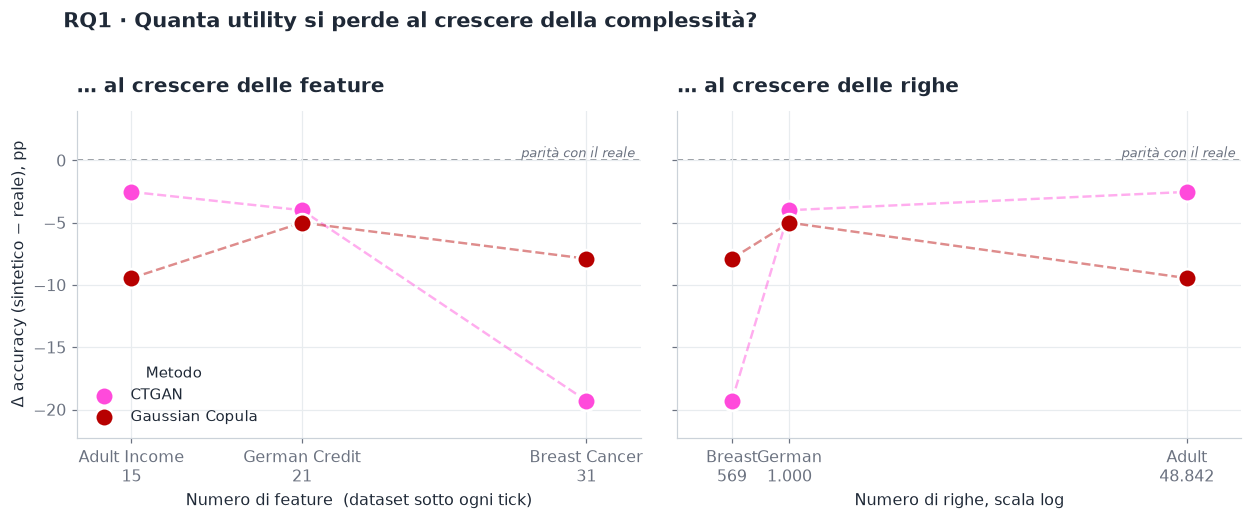

In [ ]:
def method_scatter(ax, x, y="delta_pp", connect=False, xlog=False, xticks=None, xticklabels=None, annotate=True):
    # Scatter (dataset, metodo) colorato per metodo, con etichetta del dataset accanto a ogni punto.
    for m in METHODS:
        s = agg[agg["method"] == m].sort_values(x)
        if connect and len(s) > 1:
            ax.plot(s[x], s[y], color=color_of(m), lw=1.6, ls="--", alpha=0.45, zorder=1)
        ax.scatter(s[x], s[y], s=150, color=color_of(m), edgecolor="white", linewidth=1.8, zorder=3, label=label_of(m))
        if annotate:
            for r in s.itertuples():
                ax.annotate(r.dataset_label.split()[0], (getattr(r, x), getattr(r, y)), xytext=(9, 7),
                            textcoords="offset points", fontsize=9, color=C_MUTED)
    if y == "delta_pp":
        ax.axhline(0, color=C_TEXT, ls=(0, (4, 3)), lw=1, alpha=0.6, zorder=0)
        lo, hi = ax.get_ylim(); ax.set_ylim(lo - 1, max(hi, 4))
        ax.text(0.99, 0, "parità con il reale", transform=ax.get_yaxis_transform(), ha="right", va="bottom",
                fontsize=8.5, color=C_MUTED, style="italic")
    if xlog:
        ax.set_xscale("log"); ax.xaxis.set_minor_formatter(NullFormatter())
    if xticks is not None:
        ax.set_xticks(xticks)
        if xticklabels is not None: ax.set_xticklabels(xticklabels)
        else: ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt_int(v)))
    ax.tick_params(which="minor", length=0)
    ax.margins(x=0.12)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), sharey=True)

# i dataset diventano le etichette dell'asse x: nome + valore
_d = agg.drop_duplicates("dataset")
_lab = lambda col, short=False: ([*_d.sort_values(col)[col]],
                                [f"{r.dataset_label.split()[0] if short else r.dataset_label}\n{fmt_int(getattr(r, col))}" for r in _d.sort_values(col).itertuples()])

xt, xl = _lab("n_features")
method_scatter(axes[0], "n_features", connect=True, xticks=xt, xticklabels=xl, annotate=False)
axes[0].set_xlabel("Numero di feature  (dataset sotto ogni tick)")
axes[0].set_title("… al crescere delle feature")

xt, xl = _lab("n_rows", short=True)   # nomi corti: 569 e 1.000 sono vicini in scala log
method_scatter(axes[1], "n_rows", connect=True, xlog=True, xticks=xt, xticklabels=xl, annotate=False)
axes[1].set_xlabel("Numero di righe, scala log")
axes[1].set_title("… al crescere delle righe")

axes[0].set_ylabel("Δ accuracy (sintetico − reale), pp")
axes[0].legend(title="Metodo", loc="lower left", fontsize=9.5, title_fontsize=9.5)
fig.suptitle("RQ1 · Quanta utility si perde al crescere della complessità?", x=0.055, ha="left", fontsize=14, fontweight="bold", y=1.02)
fig.tight_layout()
finish(fig, "02_delta_vs_complessita")

**Cosa notare**
* **Nessun andamento monotono.** Con Gaussian Copula il Δ non peggiora al crescere delle feature (15 → 21 → 31);
  con CTGAN sì, ma il salto è tutto su Breast Cancer, che è anche il dataset più piccolo.
* Il pannello di destra suggerisce che per CTGAN il fattore rilevante potrebbe essere la **quantità di dati**
  più che il numero di feature: il Δ più negativo in assoluto (−19 pp) è suo, e solo dove ci sono ~570 righe;
  con 48.842 righe (Adult) è invece il metodo migliore.
* Attenzione: con **3 dataset** ogni curva ha 3 punti. Questi grafici descrivono cosa è successo, non permettono
  di stimare una tendenza (vedi sezione 8).

---
## 5 · Fedeltà statistica vs utility
**Cosa mostra.** Sull'asse x l'*overall quality score* (quanto il sintetico somiglia statisticamente al reale),
sull'asse y il Δ accuracy. Se fedeltà e utility andassero di pari passo, i punti salirebbero da sinistra a destra.

**Perché è interessante.** Un sintetico può copiare bene le distribuzioni marginali e comunque perdere le relazioni
feature→target che il classificatore usa. Questo grafico dice quanto, in pratica, il quality score è un buon
proxy dell'utility.

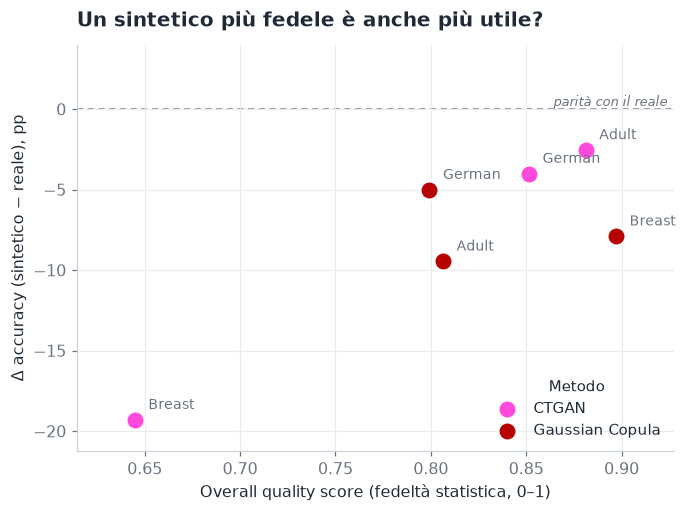

Correlazione di Pearson quality ↔ Δ: r = 0.87   (n = 6 punti: valore puramente descrittivo, non inferenziale)


In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.8))
method_scatter(ax, "quality")
ax.set_xlabel("Overall quality score (fedeltà statistica, 0–1)")
ax.set_ylabel("Δ accuracy (sintetico − reale), pp")
ax.set_title("Un sintetico più fedele è anche più utile?")
ax.legend(title="Metodo", loc="lower right", fontsize=9.5, title_fontsize=9.5)
finish(fig, "03_fedelta_vs_utility")

r = np.corrcoef(agg["quality"], agg["delta_pp"])[0, 1]
print(f"Correlazione di Pearson quality ↔ Δ: r = {r:.2f}   (n = {len(agg)} punti: valore puramente descrittivo, non inferenziale)")

**Cosa notare.** La relazione è positiva (il punto a quality più bassa è anche quello che perde di più), ma
**nella fascia di quality 0.80–0.90 i Δ vanno da circa −2.5 a −9.5 pp**: il quality score da solo non basta a
prevedere l'utility. La correlazione è inoltre guidata in buona parte da un singolo punto (Breast Cancer / CTGAN).

---
## 6 · Costo computazionale
**Cosa mostra.** Tempo di addestramento del sintetizzatore (`fit_seconds`, scala log) contro il Δ accuracy.
Il punto ideale è **in alto a sinistra**: veloce e con poca utility persa.

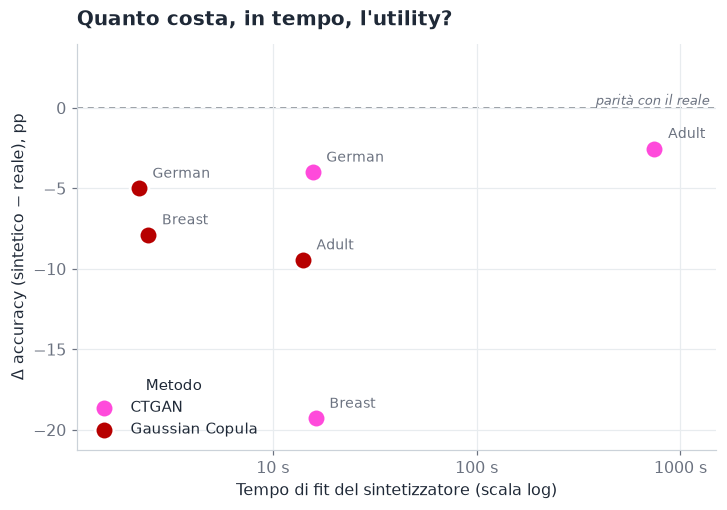

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 4.8))
method_scatter(ax, "fit_s", xlog=True)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g} s"))
ax.set_xlabel("Tempo di fit del sintetizzatore (scala log)")
ax.set_ylabel("Δ accuracy (sintetico − reale), pp")
ax.set_title("Quanto costa, in tempo, l'utility?")
ax.legend(title="Metodo", loc="lower left", fontsize=9.5, title_fontsize=9.5)
finish(fig, "04_costo_vs_utility")

**Cosa notare.** CTGAN costa da ~6 a ~50 volte più di Gaussian Copula (su Adult ~12 minuti contro ~14 secondi).
Quel costo si ripaga in utility solo su alcuni dataset (Adult: Δ da −9.5 a −2.5 pp); su Breast Cancer, invece, è
più lento **e** peggiore.

---
## 7 · Tabella di sintesi
Tutti i numeri delle sezioni precedenti, in un'unica tabella pensata per essere citata.

* **Δ (pp)**: differenza di accuracy in punti percentuali (verde = poco persa, rosso = molta persa).
* **Δ std**: deviazione standard tra repliche; `—` dove c'è una sola run (vedi 2.3 per l'affidabilità).
* **Utility retention**: quanta della *utility guadagnata sopra la baseline* dal modello reale viene mantenuta dal sintetico:

$$\text{retention} = \frac{\text{acc}_{synth} - \text{baseline}}{\text{acc}_{real} - \text{baseline}}$$

  100% = il sintetico vale quanto il reale; 0% = non meglio di predire la classe maggioritaria; negativo = peggio.
  Corregge il fatto che, con baseline alta, i Δ in pp sembrano piccoli. Attenzione su dataset dove
  `acc_real − baseline` è minuscolo (German Credit: ~4.5 pp), dove il rapporto è molto instabile.

In [ ]:
denom = agg["acc_real"] - agg["baseline"]
agg["retention"] = np.where(denom > 0, (agg["acc_synth"] - agg["baseline"]) / denom * 100, np.nan)

summary_df = pd.DataFrame({
    "Dataset": agg["dataset_label"], "Metodo": agg["method_label"], "Run": agg["n_runs"],
    "Acc. reale (%)": agg["acc_real"] * 100, "Acc. sintetico (%)": agg["acc_synth"] * 100,
    "Baseline (%)": agg["baseline"] * 100,
    "Δ (pp)": agg["delta_pp"], "Δ std": agg["delta_std"] * 100,
    "Utility retention (%)": agg["retention"],
    "Quality": agg["quality"], "Fit (s)": agg["fit_s"],
}).set_index(["Dataset", "Metodo"])

(summary_df.style
    .format({"Acc. reale (%)": "{:.1f}", "Acc. sintetico (%)": "{:.1f}", "Baseline (%)": "{:.1f}",
             "Δ (pp)": "{:+.2f}", "Δ std": "{:.2f}", "Utility retention (%)": "{:.0f}",
             "Quality": "{:.3f}", "Fit (s)": "{:.0f}"}, na_rep="—")
    .background_gradient(subset=["Δ (pp)"], cmap="RdYlGn", vmin=min(-20, summary_df["Δ (pp)"].min()), vmax=0)
    .bar(subset=["Utility retention (%)"], align="zero", color=["#F3B3B3", "#A8DADC"], vmin=-100, vmax=100)
    .set_caption("Sintesi per dataset e metodo (media sulle repliche)"))

**Export per la tesi** — la stessa tabella in LaTeX, pronta da incollare (richiede il pacchetto `booktabs`):

In [ ]:
print(summary_df.round(2).to_latex(float_format="%.2f", na_rep="--", multicolumn_format="c",
                                   caption="Utility dei dati sintetici per dataset e metodo.", label="tab:rq1-summary"))

\begin{table}
\caption{Utility dei dati sintetici per dataset e metodo.}
\label{tab:rq1-summary}
\begin{tabular}{llrrrrrrrrr}
\toprule
 &  & Run & Acc. reale (%) & Acc. sintetico (%) & Baseline (%) & Δ (pp) & Δ std & Utility retention (%) & Quality & Fit (s) \\
Dataset & Metodo &  &  &  &  &  &  &  &  &  \\
\midrule
\multirow[t]{2}{*}{Adult Income} & CTGAN & 3 & 85.76 & 83.23 & 76.07 & -2.53 & 0.00 & 73.89 & 0.88 & 744.65 \\
 & Gaussian Copula & 1 & 85.76 & 76.31 & 76.07 & -9.45 & -- & 2.48 & 0.81 & 14.03 \\
\cline{1-11}
\multirow[t]{2}{*}{German Credit} & CTGAN & 3 & 74.50 & 70.50 & 70.00 & -4.00 & 0.00 & 11.11 & 0.85 & 15.68 \\
 & Gaussian Copula & 1 & 74.50 & 69.50 & 70.00 & -5.00 & -- & -11.11 & 0.80 & 2.20 \\
\cline{1-11}
\multirow[t]{2}{*}{Breast Cancer} & CTGAN & 3 & 95.61 & 76.32 & 62.74 & -19.29 & 0.00 & 41.31 & 0.64 & 16.24 \\
 & Gaussian Copula & 1 & 95.61 & 87.72 & 62.74 & -7.89 & -- & 76.00 & 0.90 & 2.45 \\
\cline{1-11}
\bottomrule
\end{tabular}
\end{table}



---
## 8 · Limiti e prossimi passi
Cosa i risultati attuali permettono di dire, e cosa no. È utile scriverlo anche nella sezione *Limitazioni* della tesi.

**Cosa possiamo dire**
* Su tutti i dataset e con entrambi i metodi, il sintetico perde utility rispetto al reale (Δ sempre < 0).
* Nessun metodo domina: il ranking Gaussian Copula / CTGAN dipende dal dataset.
* Il quality score è correlato al Δ, ma non è un sostituto affidabile dell'utility.

**Cosa non possiamo (ancora) dire**

| Limite | Perché conta | Come risolverlo |
|---|---|---|
| **Nessuna stima di varianza tra seed** (le 3 ripetizioni CTGAN sono a seed fisso, per RQ3: 1 solo dataset sintetico) | La std è 0 per costruzione | Se vuoi barre d'errore, aggiungere run con seed diversi, in una griglia separata da quella di riproducibilità |
| **Gaussian Copula: 1 sola run** | Nessuna stima di variabilità per questo metodo | Aggiungere run con seed diversi |
| **3 soli dataset** | 3 punti non bastano per parlare di andamento con la complessità | Aggiungere dataset con feature/righe più variate |
| **Feature e righe confuse** (dataset più complesso = anche più piccolo) | Non si separa l'effetto della complessità da quello della quantità di dati | Sotto-campionare i dataset a un numero di righe fisso, o scegliere dataset che le disaccoppino |
| **Cardinalità delle categoriche assente** dall'indice | La RQ1 la cita ma nel DataFrame non c'è | Aggiungere in `aggregate.py` colonne come `n_categorical`, `max_cardinality`, `mean_cardinality` |
| **`dcr_score` sempre nullo**, `new_row_synthesis_score` mancante su German/Gaussian Copula | Nessuna analisi di privacy/novità possibile | Calcolarli nella pipeline, o rimuovere le colonne dall'indice |
| **`n_features` = colonne totali?** (Adult: 15) | Potrebbe includere la colonna target | Verificare e, se serve, usare n_features − 1 |

**Idee per estendere questo notebook** (quando i dati lo permetteranno): barre d'errore sulle repliche vere,
una regressione Δ ~ n_features + n_rows, un grafico Δ vs cardinalità media delle categoriche.